In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

# I. Cleaning the Data

### 1. Data granularity and exclusions

The original dataset contains 2,381 student records, with one row per student.

During data inspection, I identified two records associated with an Indian faculty member and the course Life Skills (Jeevan Kaushal) 2.0. These records were excluded because the course had a distinct set of quizzes that differed from those taken by the rest of the students. Since the analysis primarily focuses on Filipino learners, excluding these two records helps maintain a consistent analytical population and improves comparability across students.

The exclusion was based on differences in course and quiz structure, rather than nationality alone.

### 2. Sample selection and filtering

| Stage                                                                  | Remaining students | Excluded | % of original dataset |
| ---------------------------------------------------------------------- | ------------------ | -------- | --------------------- |
| Original dataset                                                       | 2,381              | -        | 100.00%               |
| Remove two records associated with Life Skills (Jeevan Kaushal) 2.0    | 2,379              | 2        | 99.92%                |
| Exclude students with fewer than two completed quizzes                 | 2,086              | 293      | 87.61%                |
| Restrict to courses with 14 quizzes, excluding courses with 11 quizzes | 2,048              | 38       | 86.01%                |
| Completed all 14 quizzes (none actually removed for this stage)        | 1,859              | 189      | 78.08%                |

The final analytical dataset contains 2,048 students who meet the inclusion criteria.

### 3. Selected variables and rationale

The selected variables support the analysis of students' quiz performance, course completion, and pacing relative to their enrollment and course end dates.

| Variable                            | Purpose                                                                                                                                                                                                                                              |
| ----------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `student_id`                        | Identifies each student and serves as the student-level identifier.                                                                                                                                                                                  |
| `batch_id`                          | Groups students by batch to enable cohort-level comparisons of quiz performance and completion pacing.                                                                                                                                               |
|`total_of_quizzes_incourse`.         | Number of Quizzes in the Course |
| `is_completed_all_courses`          | Indicates whether the student completed all assigned courses, providing context for interpreting their progress.                                                                                                                                     |
| `average_quiz_score`                | Serves as the primary source of truth for overall quiz performance. Although it is similar to the mean calculated from individual quiz scores, discrepancies exist, so the dataset-provided value is retained for consistency.                       |
| `lessons_average_score_in_course`   | Captures lesson-level performance, which is treated separately from quiz performance.                                                                                                                                                                |
| `total_lessons_completed_in_course` | Measures lesson completion and provides additional context on student engagement with course materials.                                                                                                                                              |
| `batch_end_date`                    | Serves as a proxy for the expected course end date and provides a reference point for assessing completion timing.                                                                                                                                   |
| `first_course_enrollment_date`      | Establishes the starting reference date for the student's course timeline. This was preferred over `batch_start_date` because quiz attempts can occur before the batch start date, whereas the enrollment date precedes the student's quiz attempts. |
| `last_quiz_attempt_date`            | Captures the date of the student's most recent quiz attempt and serves as the endpoint for calculating observed quiz activity.                                                                                                                       |

The `total_of_quizzes_incourse` and `batch_start_date` variables were not retained in the final selection. The former was unnecessary after restricting the analysis to courses with 14 quizzes, while the latter was less suitable than the student's first course enrollment date as the starting point for the timeline.

### 4. Important analytical considerations

- Quiz performance and lesson performance are distinct measures. They should not be treated as interchangeable indicators of learning.
- Completion status and pacing are also distinct. A student may complete quizzes quickly without necessarily completing all course requirements.
- The last quiz attempt is not necessarily the course completion date. It is an observable proxy for the end of quiz activity, not definitive evidence that the student finished the course on that date.
- The 14-quiz restriction improves comparability. Students taking courses with different quiz requirements may not be directly comparable in terms of quiz completion or pacing.

These criteria establish a consistent population for the subsequent analysis of quiz-taking behavior and potential early completion risk. However, unusually fast quiz completion should be interpreted as a potential risk indicator, not proof that a student failed to learn the material.

In [2]:
student_data_df = pd.read_excel('Case Assignment - Sr Associate - Philippines - data.xlsx')
student_data_df.rename(columns={'competency_quiz_score_1': 'Competency_quiz_score_1'}, inplace=True)

# get competency quiz columns 
competency_name_lists = [f"Competency_name_{i}" for i in range(1, 15)]
competency_quiz_submit_lists = [f"Competency_quiz_submit_{i}" for i in range(1, 15)]
competency_quiz_score_lists = [f"Competency_quiz_score_{i}" for i in range(1, 15)]
competency_quizzes = competency_name_lists + competency_quiz_submit_lists + competency_quiz_score_lists

# remove the two students that have a different course
student_data_df = student_data_df[student_data_df['course_name'] != 'Life Skills (Jeevan Kaushal) 2.0'].copy()
# remove students that dont have at least two answered quizzes
student_data_df = student_data_df.dropna(subset=competency_quiz_submit_lists, thresh=2)

In [3]:
competency_quiz_time_deltas = {f'Competency_quiz_delta_{i}':[] for i in range(1, 15)}
competency_quiz_time_submits = {i:[] for i in competency_quiz_submit_lists}
competency_quiz_time_score = {i:[] for i in competency_quiz_score_lists}

competency_quizzes = {
    **competency_quiz_time_deltas,
    **competency_quiz_time_submits, 
    **competency_quiz_time_score
}

In [4]:
num_missing_quizzes = (
    student_data_df[competency_quiz_submit_lists]
    .isnull()
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

num_missing_quizzes

0     1859
1       63
2       13
3       23
4       16
5       10
6       11
7       15
8       14
9        8
10      13
11      22
12      19
Name: count, dtype: int64

In [5]:
competency_quizzes = []

for _, student_row in student_data_df.iterrows():
    student_quizzes = {
        'student_id': student_row['student_id'],
        #'batch_id': student_row['batch_id'],
        'total_of_quizzes_incourse': student_row['total_of_quizzes_incourse'],
        'is_completed_all_courses': student_row['is_completed_all_courses'],
        'number_of_quiztaken': student_row['number_of_quiztaken'],
        'average_quiz_score': student_row['average_quiz_score'],
        'lessons_average_score_in_course': student_row['lessons_average_score_in_course'],
        #'average_quiz_score': student_row['average_quiz_score'],
        #'lessons_average_score_in_course': student_row['lessons_average_score_in_course'],
        #'total_lessons_completed_in_course': student_row['total_lessons_completed_in_course'],
        #'batch_end_date': student_row['batch_end_date'],
        #'batch_start_date': student_row['batch_start_date'],
        'first_course_enrollment_date': student_row['first_course_enrollment_date'],
        #'last_quiz_attempt_date': student_row['last_quiz_attempt_date']
    }

    previous_date = student_row['first_course_enrollment_date']
    cumulative_delta = 0

    for i in range(1, 15):
        submit_col = f'Competency_quiz_submit_{i}'
        score_col = f'Competency_quiz_score_{i}'
        delta_col = f'Competency_quiz_delta_{i}'
        cumsum_col = f'Competency_quiz_cumsum_{i}'

        submit_date = student_row[submit_col]
        score = student_row[score_col]

        if pd.notna(submit_date):
            delta = (submit_date - previous_date).days
            cumulative_delta += delta

            student_quizzes[submit_col] = submit_date
            student_quizzes[score_col] = score
            student_quizzes[delta_col] = delta
            student_quizzes[cumsum_col] = cumulative_delta

            previous_date = submit_date

        else:
            student_quizzes[submit_col] = pd.NaT
            student_quizzes[score_col] = None
            student_quizzes[delta_col] = pd.NaT
            student_quizzes[cumsum_col] = pd.NaT

    competency_quizzes.append(student_quizzes)

competency_quizzes_df = pd.DataFrame(competency_quizzes)
#competency_quizzes_df.to_csv('cleaned_case_assignment.csv', index=False)

# II. Exploratory Data Analysis

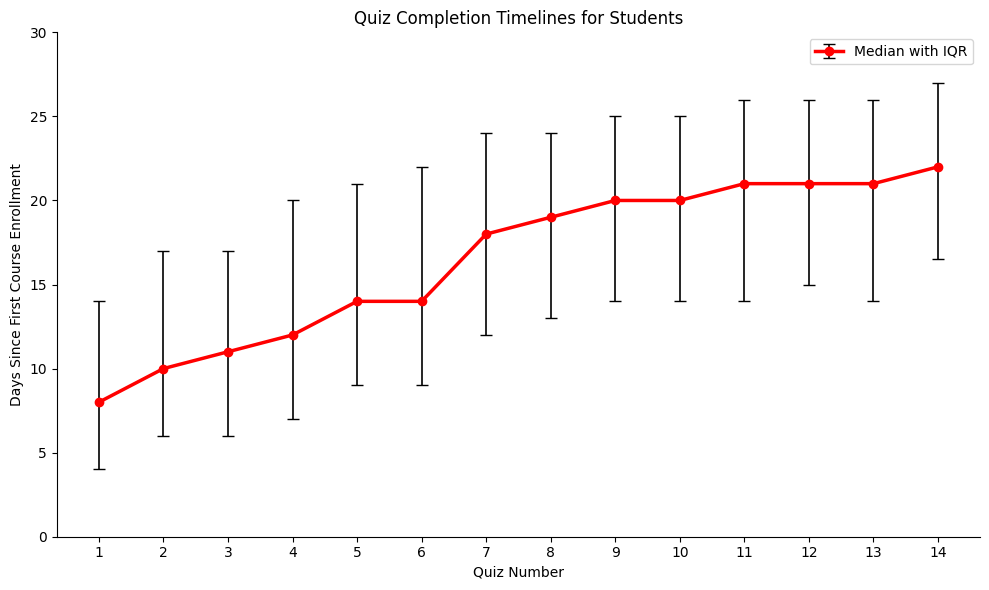

In [6]:
# Filter students who have 14 quizzes in the course.
students_14_quizzes = competency_quizzes_df[
    (competency_quizzes_df['total_of_quizzes_incourse'] == 14) &
    (competency_quizzes_df['is_completed_all_courses'] == 'Y')
]

#students_14_quizzes = competency_quizzes_df
quiz_delta_cols = list(competency_quiz_time_deltas.keys())

plt.figure(figsize=(10, 6))

all_quiz_days = []

for _, student_row in students_14_quizzes.iterrows():
    quiz_deltas = student_row[quiz_delta_cols]

    # Cumulative days since enrollment.
    quiz_days = quiz_deltas.cumsum()
    all_quiz_days.append(quiz_days.to_numpy(dtype=float))

# Calculate median and interquartile range for each quiz.
all_quiz_days = np.array(all_quiz_days)

median_quiz_days = np.nanmedian(all_quiz_days, axis=0)
q25 = np.nanpercentile(all_quiz_days, 25, axis=0)
q75 = np.nanpercentile(all_quiz_days, 75, axis=0)

# Asymmetric error bars: median down to Q1, median up to Q3.
yerr = np.array([
    median_quiz_days - q25,
    q75 - median_quiz_days
])

plt.errorbar(
    range(1, 15),
    median_quiz_days,
    yerr=yerr,
    color='red',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    linewidth=2.5,
    marker='o',
    label='Median with IQR'
)

plt.xlabel('Quiz Number')
plt.ylabel('Days Since First Course Enrollment')
plt.ylim(0, 30)
plt.title('Quiz Completion Timelines for Students')
plt.xticks(range(1, 15))
#plt.grid(True, alpha=0.3)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.legend()
plt.tight_layout()
plt.show()

# III. Construct the seven tables

## a. Get the Columns

In [7]:
institution_cols = [
    'institute_id',
    'institute_name',
    'institute_curriculum_type',
    'region_name',
    'country_name',
    'city_name',
]

faculty_cols = [
    'faculty_id', #PK
    'institute_id', # FK
    # 'faculty_email',
    # 'faculty_first_name',
    # 'faculty_last_name',
    'faculty_country_name',
    'faculty_state_name',
    'faculty_city_name',
    'faculty_district_name',
]

batch_cols = [
    'batch_id',
    'faculty_id', # FK
    'course_id', # FK
    'batch_name',
    'batch_duration',
    'batch_classification',
    'batch_created_date',
    'batch_start_date',
    'batch_end_date',
    'batch_updatedate',
    'batch_status',
    'total_number_student_enrolled',
]

course_cols = [
    'course_id',
    'course_name',
    'course_duration_hours',
    'hours_week',
    'total_lessons_in_course',
    'total_of_quizzes_incourse',
]

student_cols = [
    'student_id',
    'batch_id',
    'lmsuserid',
    # 'user_email',
    # 'user_first_name',
    # 'user_last_name',
    'user_country_name',
    'user_state_name',
    'user_city_name',
    'user_district_name',
    'user_registartion_date',
    'real_degree',
    'real_institutename',
    'actual_graduationdate',
    'student_status_inbatch',
    'batch_joined_date',
    'first_course_enrollment_date',
    # 'first_placement_date', # this is just all blanks
    # 'expected_placement_eligible_date',
    'is_completed_all_courses',
    'is_transformed_in_all_courses',
    # 'is_eligible_for_placement', # they're all zero anyways
    'Pos_Last_visited_status',
    'student_journey',
]

competency_quizzes = competency_quizzes_df.drop(
    columns=['total_of_quizzes_incourse', 'is_completed_all_courses', 'first_course_enrollment_date']
)

employment_cols = [
    'student_id', # FK
    'employmentsector',
    'employername',
    'employment_startdate',
    #'placement_reporting_date',
    #'salary_at_placement_usd',
    #'first_placement_date',
]

# Validate keys build the dimension tables

In [8]:
def select_available_columns(df, columns):
    """Select the requested columns that exist in the source DataFrame."""
    return df[[col for col in columns if col in df.columns]].copy()

In [9]:
def make_dimension(df, columns, key):
    """Build a dimension after validating its key and attributes."""
    result = select_available_columns(df, columns)

    if key not in result.columns:
        raise ValueError(f'Missing required key column: {key}')

    if result[key].isna().any():
        raise ValueError(f'{key} contains null values.')

    attributes = [
        col for col in result.columns
        if col != key
    ]

    if attributes:
        conflicts = (
            result.groupby(key, dropna=False)[attributes]
            .nunique(dropna=False)
            .gt(1)
            .any(axis=1)
        )

        if conflicts.any(): # this is to print if actually we chose our PK badly
            bad_ids = conflicts[conflicts].index.tolist()[:10]
            raise ValueError(
                f'{key} has conflicting attribute values. '
                f'Example IDs: {bad_ids}'
            )

    return result.drop_duplicates(subset=key).reset_index(drop=True)


dim_institution = make_dimension(
    student_data_df, institution_cols, 'institute_id'
)

dim_faculty = make_dimension(
    student_data_df, faculty_cols, 'faculty_id'
)

dim_batch = make_dimension(
    student_data_df, batch_cols, 'batch_id'
)

dim_course = make_dimension(
    student_data_df, course_cols, 'course_id'
)

dim_student = make_dimension(
    student_data_df, student_cols, 'student_id'
)

# Validate Foreign Keys

In [10]:
def validate_foreign_key(
    child_df,
    child_key,
    parent_df,
    parent_key,
):
    """Check that non-null child keys exist in the parent table."""
    if child_key not in child_df.columns:
        return

    if parent_key not in parent_df.columns:
        raise ValueError(f'Missing parent key: {parent_key}')

    child_values = set(child_df[child_key].dropna())
    parent_values = set(parent_df[parent_key].dropna())

    missing = child_values - parent_values

    if missing:
        raise ValueError(
            f'{child_key} contains keys absent from {parent_key}: '
            f'{list(missing)[:10]}'
        )


validate_foreign_key(
    dim_faculty, 'institute_id',
    dim_institution, 'institute_id',
)

validate_foreign_key(
    dim_batch, 'faculty_id',
    dim_faculty, 'faculty_id',
)

validate_foreign_key(
    dim_batch, 'course_id',
    dim_course, 'course_id',
)

validate_foreign_key(
    dim_student, 'batch_id',
    dim_batch, 'batch_id',
)

In [11]:
fact_employment = select_available_columns(
    student_data_df,
    employment_cols,
)

# Keep records with at least one populated employment attribute.
employment_attributes = [
    col for col in fact_employment.columns
    if col != 'student_id'
]

# create a filter if a student has any employment data
has_employment_data = fact_employment[
    employment_attributes
].notna().any(axis=1)

fact_employment = fact_employment[
    has_employment_data
].copy()

fact_employment['employment_startdate'] = pd.to_datetime(fact_employment['employment_startdate'].str[:10])

In [12]:
schema_sql = """
PRAGMA foreign_keys = ON;

CREATE TABLE IF NOT EXISTS DimInstitution (
    institute_id TEXT PRIMARY KEY NOT NULL,
    institute_name TEXT,
    institute_curriculum_type TEXT,
    region_name TEXT,
    country_name TEXT,
    city_name TEXT
);

CREATE TABLE IF NOT EXISTS DimFaculty (
    faculty_id TEXT PRIMARY KEY NOT NULL,
    institute_id TEXT NOT NULL,
    faculty_email TEXT,
    faculty_first_name TEXT,
    faculty_last_name TEXT,
    faculty_country_name TEXT,
    faculty_state_name TEXT,
    faculty_city_name TEXT,
    faculty_district_name TEXT,
    FOREIGN KEY (institute_id)
        REFERENCES DimInstitution(institute_id)
);

CREATE TABLE IF NOT EXISTS DimCourse (
    course_id TEXT PRIMARY KEY NOT NULL,
    course_name TEXT,
    course_duration_hours REAL,
    hours_week REAL,
    total_lessons_in_course INTEGER,
    total_of_quizzes_incourse INTEGER
);

CREATE TABLE IF NOT EXISTS DimBatch (
    batch_id TEXT PRIMARY KEY NOT NULL,
    faculty_id TEXT NOT NULL,
    course_id TEXT NOT NULL,
    batch_name TEXT,
    batch_duration REAL,
    batch_classification TEXT,
    batch_created_date TEXT,
    batch_start_date TEXT,
    batch_end_date TEXT,
    batch_updatedate TEXT,
    batch_status TEXT,
    enrollment_type TEXT,
    number_of_active_students INTEGER,
    total_number_student_enrolled INTEGER,

    FOREIGN KEY (faculty_id)
        REFERENCES DimFaculty(faculty_id),
    FOREIGN KEY (course_id)
        REFERENCES DimCourse(course_id)
);

CREATE TABLE IF NOT EXISTS DimStudent (
    student_id TEXT PRIMARY KEY NOT NULL,
    batch_id TEXT NOT NULL,
    lmsuserid TEXT,
    user_email TEXT,
    user_first_name TEXT,
    user_last_name TEXT,
    user_country_name TEXT,
    user_state_name TEXT,
    user_city_name TEXT,
    user_district_name TEXT,
    user_registartion_date TEXT,
    real_degree TEXT,
    real_institutename TEXT,
    actual_graduationdate TEXT,
    student_status_inbatch TEXT,
    batch_joined_date TEXT,
    first_course_enrollment_date TEXT,
    first_placement_date TEXT,
    expected_placement_eligible_date TEXT,
    is_completed_all_courses INTEGER,
    is_transformed_in_all_courses INTEGER,
    is_eligible_for_placement INTEGER,
    Pos_Last_visited_status TEXT,
    student_journey TEXT,
    FOREIGN KEY (batch_id)
        REFERENCES DimBatch(batch_id)
);

CREATE TABLE IF NOT EXISTS FactCompetencyQuiz (
    student_id TEXT PRIMARY KEY NOT NULL,

    number_of_quiztaken INTEGER,
    average_quiz_score REAL,
    lessons_average_score_in_course REAL,

    Competency_quiz_submit_1 TEXT,
    Competency_quiz_score_1 REAL,
    Competency_quiz_delta_1 REAL,
    Competency_quiz_cumsum_1 REAL,

    Competency_quiz_submit_2 TEXT,
    Competency_quiz_score_2 REAL,
    Competency_quiz_delta_2 REAL,
    Competency_quiz_cumsum_2 REAL,

    Competency_quiz_submit_3 TEXT,
    Competency_quiz_score_3 REAL,
    Competency_quiz_delta_3 REAL,
    Competency_quiz_cumsum_3 REAL,

    Competency_quiz_submit_4 TEXT,
    Competency_quiz_score_4 REAL,
    Competency_quiz_delta_4 REAL,
    Competency_quiz_cumsum_4 REAL,

    Competency_quiz_submit_5 TEXT,
    Competency_quiz_score_5 REAL,
    Competency_quiz_delta_5 REAL,
    Competency_quiz_cumsum_5 REAL,

    Competency_quiz_submit_6 TEXT,
    Competency_quiz_score_6 REAL,
    Competency_quiz_delta_6 REAL,
    Competency_quiz_cumsum_6 REAL,

    Competency_quiz_submit_7 TEXT,
    Competency_quiz_score_7 REAL,
    Competency_quiz_delta_7 REAL,
    Competency_quiz_cumsum_7 REAL,

    Competency_quiz_submit_8 TEXT,
    Competency_quiz_score_8 REAL,
    Competency_quiz_delta_8 REAL,
    Competency_quiz_cumsum_8 REAL,

    Competency_quiz_submit_9 TEXT,
    Competency_quiz_score_9 REAL,
    Competency_quiz_delta_9 REAL,
    Competency_quiz_cumsum_9 REAL,

    Competency_quiz_submit_10 TEXT,
    Competency_quiz_score_10 REAL,
    Competency_quiz_delta_10 REAL,
    Competency_quiz_cumsum_10 REAL,

    Competency_quiz_submit_11 TEXT,
    Competency_quiz_score_11 REAL,
    Competency_quiz_delta_11 REAL,
    Competency_quiz_cumsum_11 REAL,

    Competency_quiz_submit_12 TEXT,
    Competency_quiz_score_12 REAL,
    Competency_quiz_delta_12 REAL,
    Competency_quiz_cumsum_12 REAL,

    Competency_quiz_submit_13 TEXT,
    Competency_quiz_score_13 REAL,
    Competency_quiz_delta_13 REAL,
    Competency_quiz_cumsum_13 REAL,

    Competency_quiz_submit_14 TEXT,
    Competency_quiz_score_14 REAL,
    Competency_quiz_delta_14 REAL,
    Competency_quiz_cumsum_14 REAL,

    FOREIGN KEY (student_id)
        REFERENCES DimStudent(student_id)
);

CREATE TABLE IF NOT EXISTS FactEmployment (
    employment_record_id INTEGER PRIMARY KEY,
    student_id TEXT NOT NULL,
    employmentsector TEXT,
    employername TEXT,
    employment_startdate TEXT,
    placement_reporting_date TEXT,
    salary_at_placement_usd REAL,
    first_placement_date TEXT,
    FOREIGN KEY (student_id)
        REFERENCES DimStudent(student_id)
);
"""

In [13]:
db_path = Path('learning_analytics.db')

# delete it first if it exists
if db_path.exists():
    db_path.unlink()
    print('Database deleted.')
else:
    print('Database does not exist.')

tables = {
    'DimInstitution': dim_institution,
    'DimFaculty': dim_faculty,
    'DimCourse': dim_course,
    'DimBatch': dim_batch,
    'DimStudent': dim_student,
    'FactCompetencyQuiz': competency_quizzes,
    'FactEmployment': fact_employment,
}

load_order = list(tables)

with sqlite3.connect(db_path) as connection:
    connection.execute('PRAGMA foreign_keys = ON')

    # Create the schema.
    connection.executescript(schema_sql)

    # Load all seven tables in a single transaction.
    with connection:
        for table_name in load_order:
            print(f'Loading {table_name}...')
            tables[table_name].to_sql(
                name=table_name,
                con=connection,
                if_exists='append',
                index=False,
            )

print(f'Loaded database: {db_path.resolve()}')

Database deleted.
Loading DimInstitution...
Loading DimFaculty...
Loading DimCourse...
Loading DimBatch...
Loading DimStudent...
Loading FactCompetencyQuiz...
Loading FactEmployment...
Loaded database: /Users/jfv/Desktop/wadhwani/11_Case_Study/learning_analytics.db


In [15]:
output_path = Path('learning_analytics.xlsx')

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    for table_name, df in tables.items():
        export_df = df.copy()

        for column in export_df.select_dtypes(
            include=['timedelta64[ns]']
        ).columns:
            export_df[column] = (
                export_df[column].dt.total_seconds()
            )

        export_df.to_excel(
            writer,
            sheet_name=table_name,
            index=False,
        )

print(f'Exported to: {output_path.resolve()}')

Exported to: /Users/jfv/Desktop/wadhwani/11_Case_Study/learning_analytics.xlsx
